# Task 4: Email/SMS Spam Detection with Machine Learning
**Objective:** Build an NLP binary classifier that separates spam from legitimate (ham) messages.

**Tech stack:** Python, pandas, scikit-learn (TF-IDF, Naive Bayes, Logistic Regression, SVM), NLTK, WordCloud

**Dataset:** SMS Spam Collection (5,572 messages labelled ham/spam). Keep `sms.tsv` in the same folder as this notebook.

## 1. Import Libraries

In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

nltk.download('stopwords', quiet=True)
sns.set_theme(style='whitegrid')

## 2. Load the Dataset

In [2]:
# The file is tab-separated with no header: label <TAB> message
df = pd.read_csv('sms.tsv', sep='\t', names=['label', 'message'])
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Data Inspection and Class Distribution

Shape: (5572, 2)

Null values:
label      0
message    0
dtype: int64

Duplicate messages: 403

Class distribution:
       count  percent
label                
ham     4825    86.59
spam     747    13.41


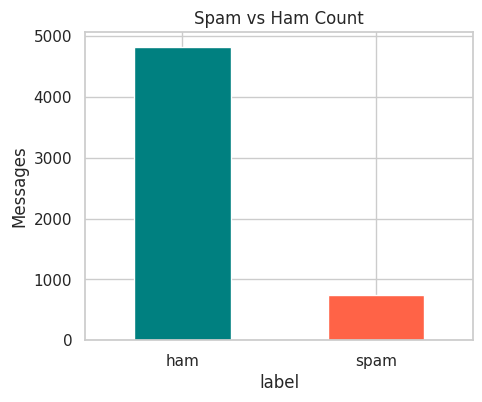

In [3]:
print('Shape:', df.shape)
print('\nNull values:')
print(df.isnull().sum())
print('\nDuplicate messages:', df.duplicated().sum())

counts = df['label'].value_counts()
percent = df['label'].value_counts(normalize=True).mul(100).round(2)
print('\nClass distribution:')
print(pd.DataFrame({'count': counts, 'percent': percent}))

counts.plot(kind='bar', color=['teal', 'tomato'], figsize=(5, 4))
plt.title('Spam vs Ham Count'); plt.xticks(rotation=0); plt.ylabel('Messages')
plt.show()

**Observation:** The dataset is **imbalanced**: most messages are ham and only about 13% are spam. Because of this, plain accuracy can look high even for a poor model, so we also look at precision, recall and F1 for the spam class.

### 3.1 Remove duplicates
Identical messages can appear in both the train and test sets, which would make the results look better than they really are. We drop them before splitting.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)
print(df['label'].value_counts())

Shape after removing duplicates: (5169, 2)
label
ham     4516
spam     653
Name: count, dtype: int64


## 4. Text Preprocessing
Steps: lowercase, remove punctuation/numbers, remove stopwords, stemming.

- **Stopwords** are very common words (the, is, and) that carry little meaning.
- **Stemming** cuts words to their root (winning, wins, win become *win*) so related words are counted together.

In [5]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess(text):
    text = text.lower()                          # 1. lowercase
    text = re.sub(r'[^a-z\s]', ' ', text)        # 2. remove punctuation and digits
    tokens = text.split()
    tokens = [w for w in tokens if w not in stop_words]   # 3. remove stopwords
    tokens = [stemmer.stem(w) for w in tokens]            # 4. stemming
    return ' '.join(tokens)

df['clean'] = df['message'].apply(preprocess)
df[['message', 'clean']].head()

,message,clean
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


### 4.1 Message length (extra EDA)

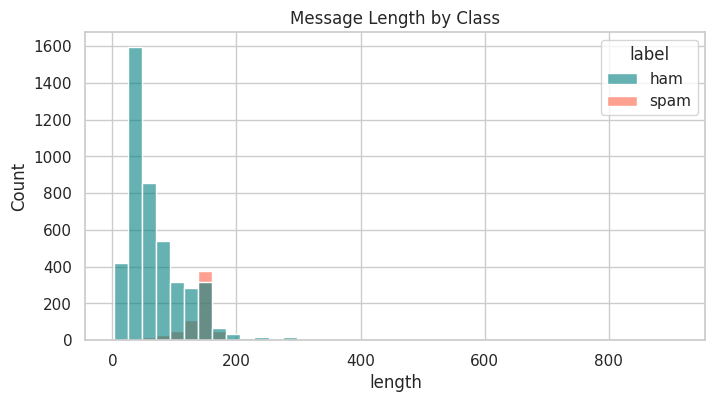

label
ham      70.9
spam    137.7
Name: length, dtype: float64


In [6]:
df['length'] = df['message'].str.len()
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='length', hue='label', bins=40, palette=['teal', 'tomato'], alpha=0.6)
plt.title('Message Length by Class')
plt.show()
print(df.groupby('label')['length'].mean().round(1))

## 5. Feature Extraction with TF-IDF
**What TF-IDF measures:** TF-IDF (Term Frequency - Inverse Document Frequency) gives each word a weight that reflects how important it is to a message.

- **TF** (term frequency): how often the word appears in this message. More occurrences means a higher weight.
- **IDF** (inverse document frequency): how rare the word is across *all* messages. Common words like "ok" get a low weight; rare, distinctive words like "prize" get a high weight.

TF-IDF = TF x IDF. Words that are frequent in one message but rare overall get the highest scores, which makes them good clues for classification.

## 6. Train/Test Split (80/20)
We split **before** fitting TF-IDF so the vectoriser only learns vocabulary from the training data (this avoids data leakage). `stratify=y` keeps the spam ratio the same in both sets.

In [7]:
y = (df['label'] == 'spam').astype(int)   # spam = 1, ham = 0
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df['clean'], y, test_size=0.2, random_state=42, stratify=y)

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train = tfidf.fit_transform(X_train_txt)
X_test = tfidf.transform(X_test_txt)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Spam share in train: %.1f%% | test: %.1f%%' % (y_train.mean()*100, y_test.mean()*100))

Train: (4135, 5000) | Test: (1034, 5000)
Spam share in train: 12.6% | test: 12.7%


## 7. Train and Evaluate Classifiers
1. **Multinomial Naive Bayes** (standard for text)
2. **Logistic Regression**
3. **Linear SVM**

In [8]:
models = {
    'Multinomial Naive Bayes': MultinomialNB(alpha=0.1),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Linear SVM': LinearSVC(class_weight='balanced', random_state=42),
}

rows, preds = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    preds[name] = p
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, p),
        'Precision': precision_score(y_test, p),
        'Recall': recall_score(y_test, p),
        'F1': f1_score(y_test, p),
    })

results = pd.DataFrame(rows).set_index('Model').round(4)
results.sort_values('F1', ascending=False)

,Accuracy,Precision,Recall,F1
Model,,,,
Multinomial Naive Bayes,0.9797,0.9508,0.8855,0.9170
Linear SVM,0.9778,0.9091,0.9160,0.9125
Logistic Regression,0.9739,0.8768,0.9237,0.8996


Precision, recall and F1 above are for the **spam** class (the class we care about).

### 7.1 Classification reports and confusion matrices

Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham       0.98      0.99      0.99       903
        spam       0.95      0.89      0.92       131

    accuracy                           0.98      1034
   macro avg       0.97      0.94      0.95      1034
weighted avg       0.98      0.98      0.98      1034



Logistic Regression
              precision    recall  f1-score   support

         ham       0.99      0.98      0.98       903
        spam       0.88      0.92      0.90       131

    accuracy                           0.97      1034
   macro avg       0.93      0.95      0.94      1034
weighted avg       0.97      0.97      0.97      1034

Linear SVM
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.91      0.92      0.91       131

    accuracy                           0.98      1034
   macro avg       0.95      0.95      0.95      1034
weighted avg       0.98      0.98      0.98      1034



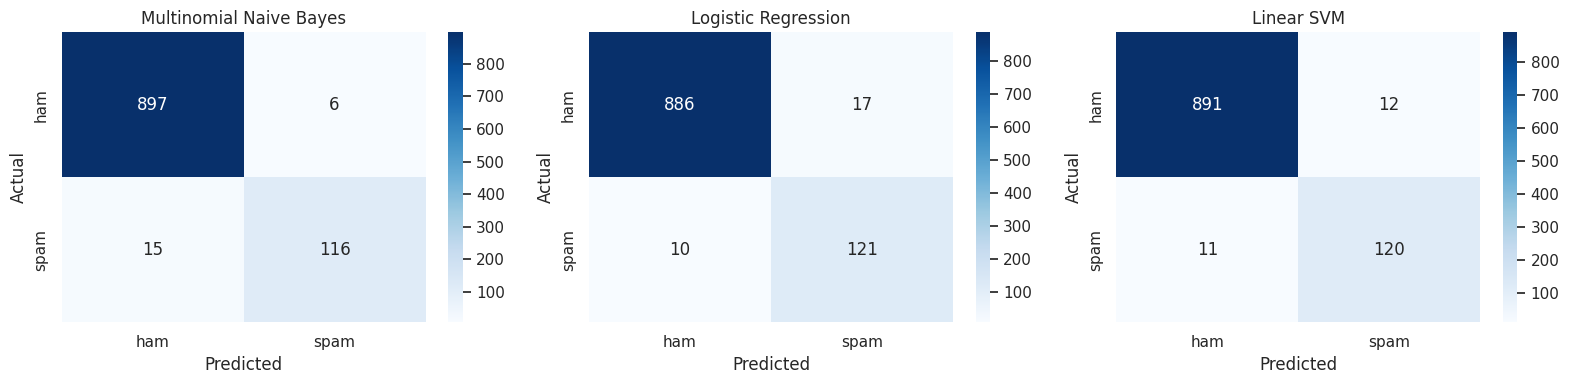

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, p) in zip(axes, preds.items()):
    print('=' * 55); print(name); print('=' * 55)
    print(classification_report(y_test, p, target_names=['ham', 'spam']))
    cm = confusion_matrix(y_test, p)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

**Observation:** All three models perform very well (accuracy 97-98%). They differ in the precision/recall balance for spam:
- **Naive Bayes** has the highest precision (95%) and highest F1 (0.917), so it rarely marks a genuine message as spam, but it misses more spam (recall 88.6%).
- **Logistic Regression** has the highest recall (92.4%) but the lowest precision (87.7%), so it catches more spam but also flags more genuine messages.
- **Linear SVM** sits in the middle on both.

### 7.2 Model comparison

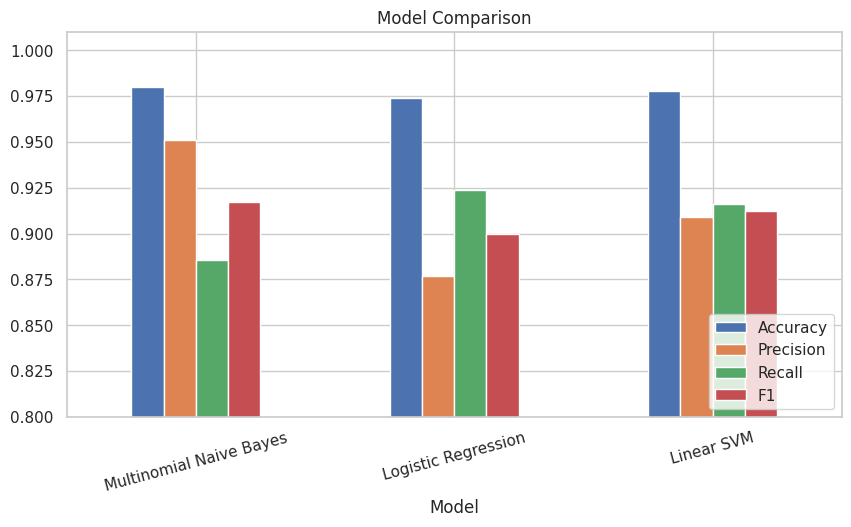

In [10]:
results.plot(kind='bar', figsize=(10, 5), ylim=(0.8, 1.01))
plt.title('Model Comparison'); plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.show()

### 7.3 Test on new messages

In [11]:
samples = [
    'Congratulations! You have won a free prize. Call now to claim your reward',
    'Hey, are we still meeting for lunch tomorrow?',
    'URGENT! Your account has been selected for a cash bonus, text WIN to 80082',
    'Can you send me the notes from yesterday class',
]
best = models['Multinomial Naive Bayes']
pred = best.predict(tfidf.transform([preprocess(s) for s in samples]))
for s, p in zip(samples, pred):
    print(('SPAM' if p else 'HAM ').ljust(5), '|', s)

SPAM  | Congratulations! You have won a free prize. Call now to claim your reward
HAM   | Hey, are we still meeting for lunch tomorrow?
SPAM  | URGENT! Your account has been selected for a cash bonus, text WIN to 80082
HAM   | Can you send me the notes from yesterday class


## 8. Why is Recall Important for Spam Detection?

**Recall** = TP / (TP + FN): of all the real spam messages, how many did the model catch?

A low recall means many spam messages slip through into the inbox (false negatives). These can be phishing, scams or malware links, so missing them is risky for users.

There is a trade-off with **precision**. A false positive means a genuine (ham) message is marked as spam, and the user might miss an important email. In practice, spam filters aim for **high recall while keeping precision very high**, which is why we look at the **F1-score** (the balance of both) and not accuracy alone. Because spam is only about 13% of the data, a model that predicts "ham" for everything would still get about 87% accuracy while catching zero spam.

## 9. (Bonus) WordClouds

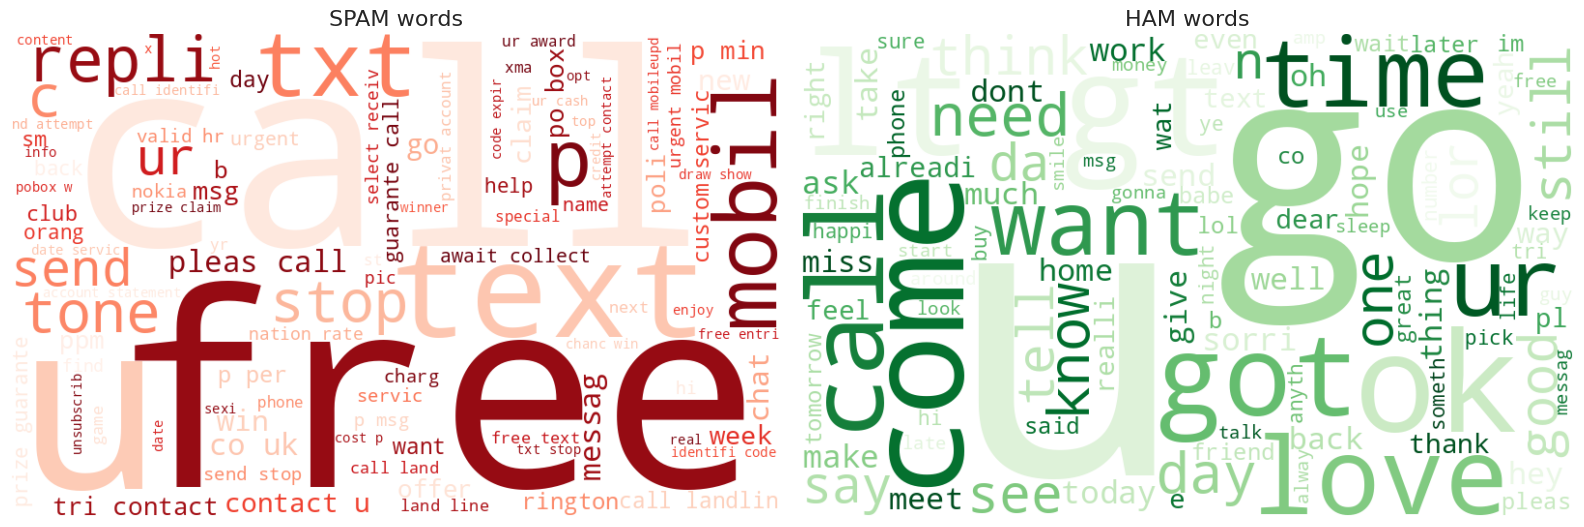

In [12]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, label, cmap in zip(axes, ['spam', 'ham'], ['Reds', 'Greens']):
    text = ' '.join(df.loc[df['label'] == label, 'clean'])
    wc = WordCloud(width=800, height=500, background_color='white',
                   colormap=cmap, max_words=100).generate(text)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(f'{label.upper()} words', fontsize=16)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Most spam-indicating words (from Naive Bayes)

claim          6.13
prize          6.10
tone           5.83
co uk          5.44
guarante       5.41
rington        5.40
ppm            5.30
cs             5.14
www            5.09
attempt        5.02
tri contact    4.99
landlin        4.95
pobox          4.94
entri          4.91
poli           4.91
dtype: float64


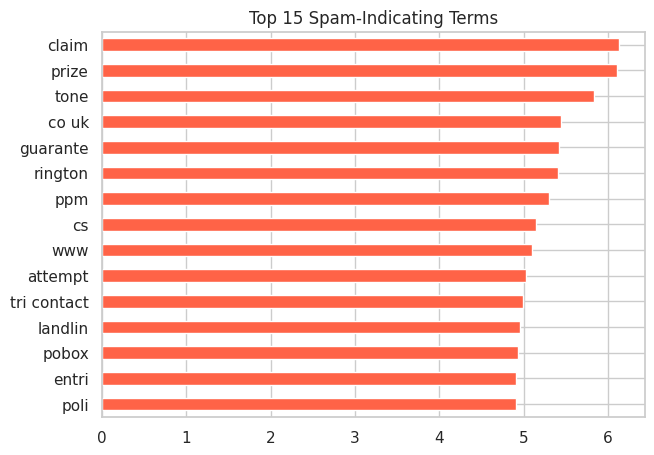

In [13]:
nb = models['Multinomial Naive Bayes']
words = np.array(tfidf.get_feature_names_out())
log_ratio = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
top = pd.Series(log_ratio, index=words).sort_values(ascending=False).head(15)
print(top.round(2))
top[::-1].plot(kind='barh', color='tomato', figsize=(7, 5))
plt.title('Top 15 Spam-Indicating Terms'); plt.show()

## 10. Conclusion

| Model | Accuracy | Precision (spam) | Recall (spam) | F1 (spam) |
|---|---|---|---|---|
| Multinomial Naive Bayes | 0.9797 | 0.9508 | 0.8855 | 0.9170 |
| Linear SVM | 0.9778 | 0.9091 | 0.9160 | 0.9125 |
| Logistic Regression | 0.9739 | 0.8768 | 0.9237 | 0.8996 |

- **Best model: Multinomial Naive Bayes.** It has the highest accuracy (97.97%) and highest spam F1 (0.917), and it is the fastest and simplest of the three. Linear SVM is a very close second with a better balance of precision and recall.
- **Trade-off:** If the priority is catching every spam message (maximum recall), Logistic Regression is the better choice, at the cost of more false alarms.
- **Key spam words:** claim, prize, tone, guarantee, www, pobox. Spam messages are also about twice as long on average (138 vs 71 characters).
- **Data note:** 403 duplicate messages were removed before splitting to avoid leakage between train and test. The dataset is imbalanced (about 13% spam), so F1 and recall were used along with accuracy.
- **Limitations:** The results come from a single train/test split on SMS messages. Email spam is longer and more varied, so the model may need retraining on email data.